# var1: validation

Does the classical generator (3-factor PCA, VAR(1), Student-t shocks, constant volatility) produce credible 250-day curve distributions? Two designs, both judged descriptively (about 7 to 11 independent years only):

- **Design A:** one cut. Fit on data up to the end of 2018, simulate from that curve, compare with realised 250-day changes whose start date is at or after the cut.
- **Design B:** expanding window. Origins at every year-end 2012-2022, each tested on the windows starting in the following year.

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
from scenario_lab.data import load_curve
from scenario_lab.models import var1 as m
from scenario_lab import validation as v

levels = load_curve("AAA")
changes = levels.diff().dropna()
FIT_END = v.FIT_END
print("fit end:", FIT_END)

fit end: 2018-12-31


## Design A: single cut (end-2018)

### Fit and simulate

In [2]:
p = m.fit(changes.loc[:FIT_END])
y0 = levels.loc[:FIT_END].iloc[-1].values
curves = m.simulate(p, y0)
sim_changes = curves[:, -1] - curves[:, 0]          # (paths, 6)
print("curves", curves.shape, "sim_changes", sim_changes.shape)
print("df", p.df.round(2), "sigma", p.sigma.round(4))

curves (25000, 251, 6) sim_changes (25000, 6)
df [5.24 3.04 3.  ] sigma [0.0805 0.0367 0.0192]


### Simulated vs realised quantiles (test windows)

In [3]:
realised = v.realised_changes(levels)
test = realised.loc[FIT_END:]                        # strict: window starts at or after the cut
print("test windows:", len(test), "from", test.index[0].date(), "to", test.index[-1].date())
print("effective independent years: about", round(len(test) / 250, 1))
print()
print("simulated")
print(v.horizon_quantiles(curves).round(2))
print()
print("realised (test)")
print(test.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(2))

test windows: 1764 from 2019-01-02 to 2025-11-26
effective independent years: about 7.1

simulated
        1Y    2Y    5Y   10Y   20Y   30Y
0.05 -0.70 -0.96 -1.01 -1.02 -1.16 -1.35
0.25 -0.28 -0.39 -0.42 -0.42 -0.47 -0.56
0.50  0.00  0.01  0.00 -0.00 -0.00 -0.00
0.75  0.28  0.40  0.42  0.42  0.47  0.56
0.95  0.70  0.96  1.01  1.04  1.16  1.35

realised (test)
        1Y    2Y    5Y   10Y   20Y   30Y
0.05 -1.19 -0.95 -0.45 -0.45 -0.56 -0.61
0.25 -0.15 -0.11 -0.12 -0.02  0.08  0.06
0.50  0.03  0.06  0.15  0.28  0.34  0.35
0.75  0.84  0.93  0.80  0.67  0.74  0.77
0.95  3.20  2.75  2.45  2.24  1.97  1.85


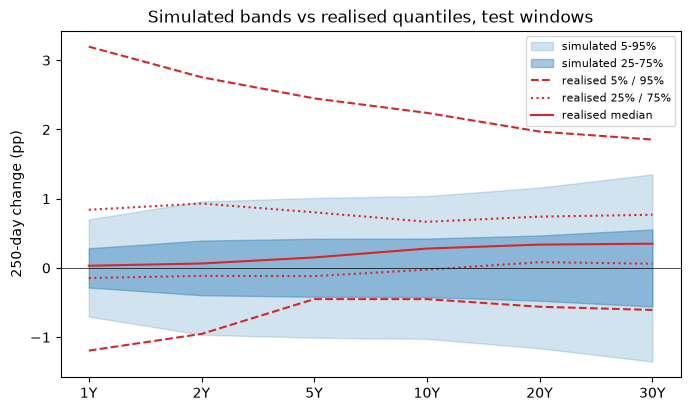

In [4]:
import matplotlib.pyplot as plt
plt.style.use("default"); plt.rcParams["figure.facecolor"] = "white"

sim_q = v.horizon_quantiles(curves)
real_q = test.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
x = np.arange(len(sim_q.columns))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.fill_between(x, sim_q.loc[0.05], sim_q.loc[0.95], alpha=0.2, color="C0", label="simulated 5-95%")
ax.fill_between(x, sim_q.loc[0.25], sim_q.loc[0.75], alpha=0.4, color="C0", label="simulated 25-75%")
ax.plot(x, real_q.loc[0.05], "C3--", label="realised 5% / 95%")
ax.plot(x, real_q.loc[0.95], "C3--")
ax.plot(x, real_q.loc[0.25], "C3:", label="realised 25% / 75%")
ax.plot(x, real_q.loc[0.75], "C3:")
ax.plot(x, real_q.loc[0.5], "C3-", label="realised median")
ax.axhline(0, color="k", lw=0.5)
ax.set_xticks(x); ax.set_xticklabels(sim_q.columns)
ax.set_ylabel("250-day change (pp)")
ax.set_title("Simulated bands vs realised quantiles, test windows")
ax.legend(fontsize=8)
plt.show()

### Coverage (test windows)

Fraction of realised 250-day changes inside the simulated band. Nominal 0.90 for 5-95%, 0.50 for 25-75%.

In [5]:
cov90 = v.coverage(sim_changes, test, 0.05, 0.95)
cov50 = v.coverage(sim_changes, test, 0.25, 0.75)
print("type:", type(cov90), "index:", list(cov90.index))
print(pd.DataFrame({"5-95% (nominal 90%)": cov90, "25-75% (nominal 50%)": cov50}).round(3))

type: <class 'pandas.Series'> index: ['1Y', '2Y', '5Y', '10Y', '20Y', '30Y']
     5-95% (nominal 90%)  25-75% (nominal 50%)
1Y                 0.563                 0.397
2Y                 0.708                 0.494
5Y                 0.789                 0.573
10Y                0.811                 0.544
20Y                0.840                 0.536
30Y                0.885                 0.580


### Coverage on the training windows (in sample)

Should be near nominal if the model describes its own training data.

In [6]:
train = realised.loc[:FIT_END].iloc[:-250]            # windows that end inside the training window
print(pd.DataFrame({"5-95%": v.coverage(sim_changes, train, 0.05, 0.95),
                    "25-75%": v.coverage(sim_changes, train, 0.25, 0.75)}).round(3))

     5-95%  25-75%
1Y   0.734   0.489
2Y   0.809   0.546
5Y   0.873   0.483
10Y  0.912   0.538
20Y  0.942   0.598
30Y  0.967   0.644


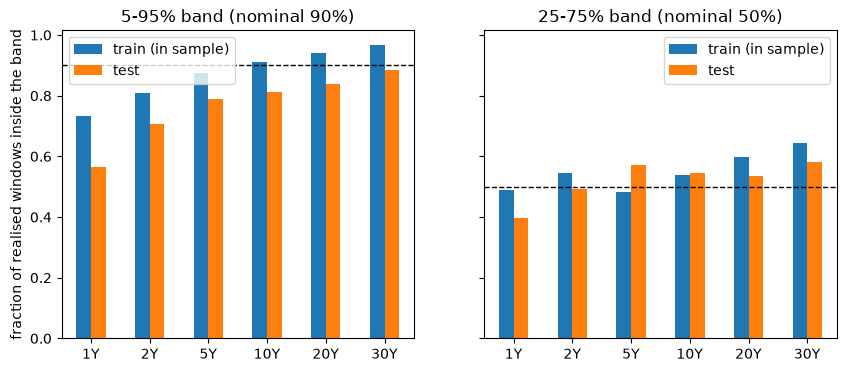

In [7]:
cov = {"test 5-95%": v.coverage(sim_changes, test, 0.05, 0.95),
       "train 5-95%": v.coverage(sim_changes, train, 0.05, 0.95),
       "test 25-75%": v.coverage(sim_changes, test, 0.25, 0.75),
       "train 25-75%": v.coverage(sim_changes, train, 0.25, 0.75)}

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, band, nominal in zip(axes, ["5-95%", "25-75%"], [0.9, 0.5]):
    pd.DataFrame({"train (in sample)": cov[f"train {band}"], "test": cov[f"test {band}"]}).plot.bar(ax=ax, rot=0)
    ax.axhline(nominal, color="k", ls="--", lw=1)
    ax.set_title(f"{band} band (nominal {nominal:.0%})")
axes[0].set_ylabel("fraction of realised windows inside the band")
plt.show()

### Daily moments: simulated vs actual

Pool all simulated daily changes `(paths * 250, 6)` and compare std, excess kurtosis and the correlation matrix with the actual daily changes, in sample (up to the cut) and out of sample (after it). The Student-t shocks are floored at df = 3, so the fourth moment is infinite and simulated kurtosis is unstable; read it as an order of magnitude.

In [8]:
sim_daily = np.diff(curves, axis=1).reshape(-1, 6)
mom = {"simulated": v.daily_moments(sim_daily),
       "actual train": v.daily_moments(changes.loc[:FIT_END].values),
       "actual test": v.daily_moments(changes.loc[FIT_END:].values)}
cols = levels.columns
print(pd.DataFrame({k: v["std"] for k, v in mom.items()}, index=cols).round(4))
print()
print(pd.DataFrame({k: v["excess_kurt"] for k, v in mom.items()}, index=cols).round(1))
print()
for k in ["actual train", "actual test"]:
    d = mom["simulated"]["corr_matrix"] - mom[k]["corr_matrix"]
    print(f"corr(simulated) - corr({k}), max abs difference: {np.abs(d).max():.2f}")
print(pd.DataFrame(mom["simulated"]["corr_matrix"], index=cols, columns=cols).round(2))
print(pd.DataFrame(mom["actual train"]["corr_matrix"], index=cols, columns=cols).round(2))

     simulated  actual train  actual test
1Y      0.0235        0.0246       0.0333
2Y      0.0330        0.0334       0.0446
5Y      0.0366        0.0373       0.0468
10Y     0.0376        0.0378       0.0462
20Y     0.0406        0.0413       0.0466
30Y     0.0471        0.0473       0.0461

     simulated  actual train  actual test
1Y        28.4          12.6         23.9
2Y        16.3           8.9         10.4
5Y         5.9           2.4          5.4
10Y        8.3           1.8          3.4
20Y        4.9           3.1          2.4
30Y        6.6           8.7          2.0

corr(simulated) - corr(actual train), max abs difference: 0.09
corr(simulated) - corr(actual test), max abs difference: 0.16
       1Y    2Y    5Y   10Y   20Y   30Y
1Y   1.00  0.98  0.79  0.52  0.40  0.38
2Y   0.98  1.00  0.90  0.68  0.53  0.47
5Y   0.79  0.90  1.00  0.92  0.76  0.62
10Y  0.52  0.68  0.92  1.00  0.92  0.78
20Y  0.40  0.53  0.76  0.92  1.00  0.96
30Y  0.38  0.47  0.62  0.78  0.96  1.00
     

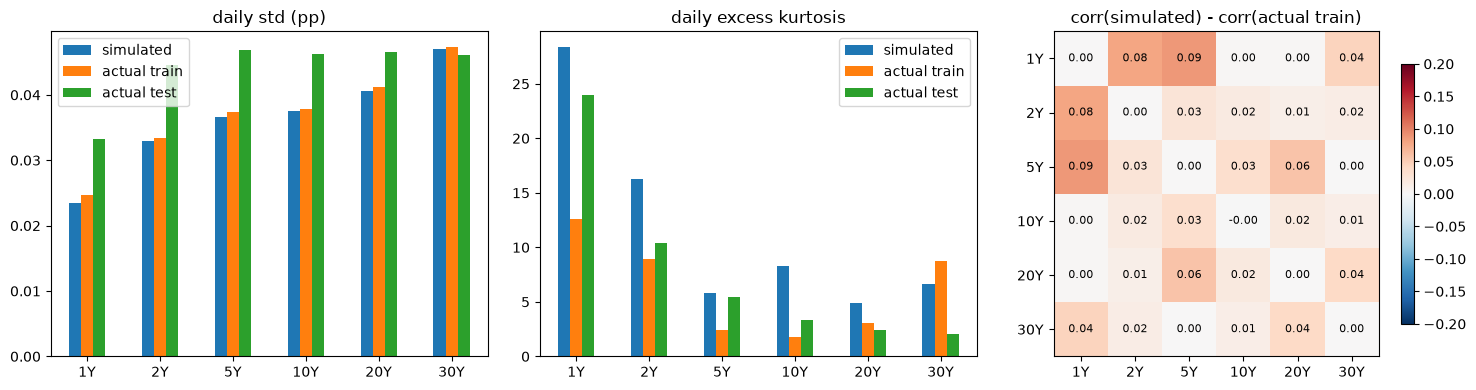

In [9]:
from matplotlib.colors import TwoSlopeNorm
std = pd.DataFrame({k: v["std"] for k, v in mom.items()}, index=cols)
kurt = pd.DataFrame({k: v["excess_kurt"] for k, v in mom.items()}, index=cols)
dcorr = pd.DataFrame(mom["simulated"]["corr_matrix"] - mom["actual train"]["corr_matrix"], index=cols, columns=cols)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
std.plot.bar(ax=axes[0], rot=0); axes[0].set_title("daily std (pp)")
kurt.plot.bar(ax=axes[1], rot=0); axes[1].set_title("daily excess kurtosis")
im = axes[2].imshow(dcorr.values, cmap="RdBu_r", norm=TwoSlopeNorm(vcenter=0, vmin=-0.2, vmax=0.2))
axes[2].set_xticks(range(6)); axes[2].set_xticklabels(cols)
axes[2].set_yticks(range(6)); axes[2].set_yticklabels(cols)
for i in range(6):
    for j in range(6):
        axes[2].text(j, i, f"{dcorr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
axes[2].set_title("corr(simulated) - corr(actual train)")
fig.colorbar(im, ax=axes[2], shrink=0.8)
plt.tight_layout(); plt.show()

### Findings, design A

**Horizon (250-day changes)**
- **Short end too narrow, long end too wide.** Test coverage of the 5-95% band is 0.56 (1Y), 0.71 (2Y), 0.79 (5Y), 0.81 (10Y), 0.84 (20Y), 0.89 (30Y) against a nominal 0.90. The 25-75% band is about 0.5 except at 1Y (0.40), so the centre is mostly right.
- **Not only a test-period effect.** In sample the 30Y band covers 97% and the 1Y band 73%: too wide at the long end and too narrow at the short end on the model's own training data. Consistent with no mean reversion and a constant volatility.
- **The 2022 hikes dominate the test set.** Realised 1Y changes reach +3.2pp at the 95th percentile against +0.7pp simulated.

**Daily moments**
- **Std matches in sample** (simulated 0.024-0.047 against actual train 0.025-0.047). The test period is more volatile at the short end (1Y 0.033, 2Y 0.045).
- **Correlations are close:** max abs difference 0.09 against train, 0.16 against test. The model makes 1Y-2Y too correlated (0.98 against 0.90): three factors leave out the residual noise.
- **Kurtosis is only indicative** (infinite 4th moment at the df = 3 floor): simulated 28 at 1Y against 13 actual in sample.

**Caveat:** 1,764 overlapping test windows contain about 7 independent years, so only large gaps from nominal mean anything.

## Design B: expanding window (origins at every year-end 2012-2022)

At each origin: fit on data up to the origin, simulate 250 days, test on the 250 windows that start in the following year. Every window is tested once, against the model fitted just before it. Values are the fraction of those windows inside the band (rows = origin year, columns = maturity).

### Coverage by origin

In [10]:
origins = [f"{y}-12-31" for y in range(2012, 2023)]
cov90, cov50, sim_std, act_std = {}, {}, {}, {}

for o in origins:
    p_o = m.fit(changes.loc[:o])
    y0_o = levels.loc[:o].iloc[-1].values
    curves_o = m.simulate(p_o, y0_o)
    sim_o = curves_o[:, -1] - curves_o[:, 0]
    test = realised[realised.index > o].iloc[:250]
    cov90[o] = v.coverage(sim_o, test, 0.05, 0.95)
    cov50[o] = v.coverage(sim_o, test, 0.25, 0.75)
    sim_std[o] = np.diff(curves_o, axis=1).reshape(-1, 6).std(axis=0)          # simulated daily std
    act_std[o] = changes[changes.index > o].iloc[:250].std().values            # actual daily std in the test year

table90 = pd.DataFrame(cov90).T      # rows = origins, columns = maturities
print(table90.round(3))
print(table90.mean().round(3))

               1Y     2Y     5Y    10Y    20Y    30Y
2012-12-31  1.000  1.000  1.000  0.808  0.948  1.000
2013-12-31  1.000  1.000  1.000  0.640  0.580  0.684
2014-12-31  1.000  1.000  1.000  0.972  0.924  1.000
2015-12-31  1.000  1.000  1.000  1.000  1.000  1.000
2016-12-31  1.000  1.000  1.000  1.000  1.000  1.000
2017-12-31  1.000  1.000  1.000  0.936  0.920  1.000
2018-12-31  1.000  1.000  1.000  1.000  1.000  1.000
2019-12-31  1.000  1.000  1.000  1.000  1.000  1.000
2020-12-31  0.452  0.408  0.268  0.312  0.448  0.520
2021-12-31  0.000  0.056  0.300  0.372  0.444  0.656
2022-12-31  0.692  0.924  1.000  1.000  1.000  1.000
1Y     0.831
2Y     0.853
5Y     0.870
10Y    0.822
20Y    0.842
30Y    0.896
dtype: float64


### Heatmap

Blue: band too wide (above nominal). Red: band too narrow (below nominal). White: calibrated.

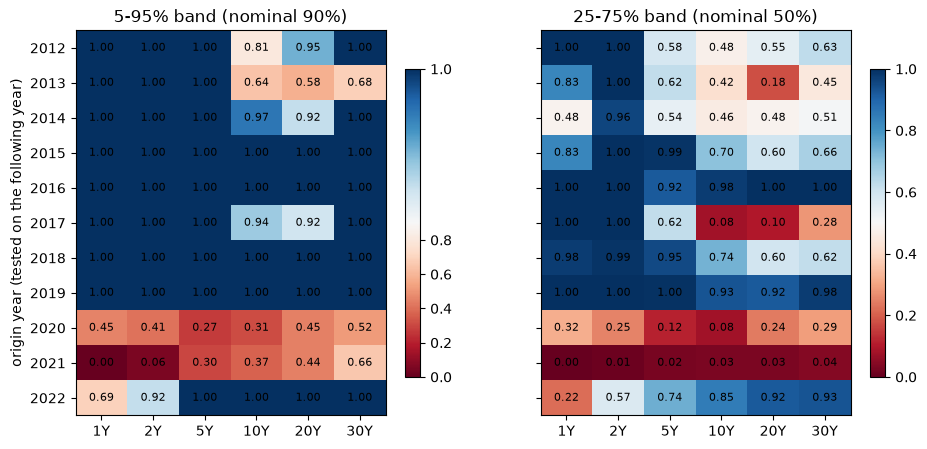

In [11]:
from matplotlib.colors import TwoSlopeNorm

table50 = pd.DataFrame(cov50).T
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, tab, nominal, title in zip(axes, [table90, table50], [0.9, 0.5], ["5-95% band", "25-75% band"]):
    im = ax.imshow(tab.values, cmap="RdBu", norm=TwoSlopeNorm(vcenter=nominal, vmin=0, vmax=1), aspect="auto")
    ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(tab.columns)
    ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels([o[:4] for o in tab.index])
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            ax.text(j, i, f"{tab.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"{title} (nominal {nominal:.0%})")
    fig.colorbar(im, ax=ax, shrink=0.8)
axes[0].set_ylabel("origin year (tested on the following year)")
plt.show()

### Daily std by origin

Simulated daily std (fit up to the origin) divided by the actual daily std in the following year. 1.0 is calibrated, above 1 means the model is too volatile for that year, below 1 too calm. Only the std is compared here: with about 250 actual days per year, kurtosis and correlations are too noisy.

              1Y    2Y    5Y   10Y   20Y   30Y
2012-12-31  2.25  1.76  1.13  1.01  1.17  1.40
2013-12-31  2.94  2.97  1.82  1.36  1.37  1.75
2014-12-31  1.99  2.49  1.40  0.80  0.66  0.76
2015-12-31  2.38  2.75  1.65  1.16  0.95  1.01
2016-12-31  1.62  2.04  1.56  1.31  1.26  1.40
2017-12-31  2.36  2.44  1.62  1.48  1.62  1.86
2018-12-31  2.00  2.35  1.66  1.26  1.13  1.21
2019-12-31  1.44  1.51  1.16  1.00  0.99  1.08
2020-12-31  2.26  2.35  1.54  1.32  1.37  1.56
2021-12-31  0.45  0.42  0.45  0.51  0.57  0.67
2022-12-31  0.43  0.48  0.58  0.61  0.64  0.72


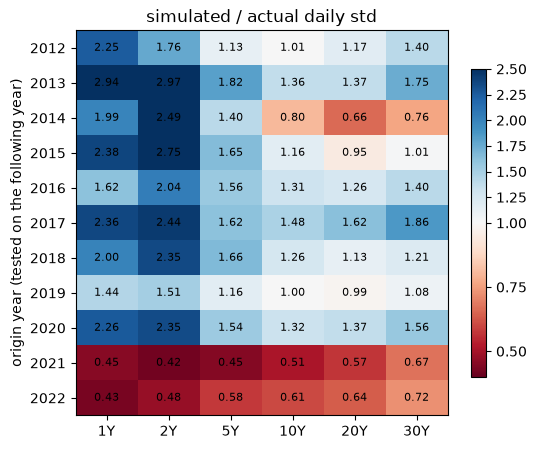

In [12]:
ratio = pd.DataFrame(sim_std, index=levels.columns).T / pd.DataFrame(act_std, index=levels.columns).T
print(ratio.round(2))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(ratio.values, cmap="RdBu", norm=TwoSlopeNorm(vcenter=1, vmin=0.4, vmax=2.5), aspect="auto")
ax.set_xticks(range(6)); ax.set_xticklabels(ratio.columns)
ax.set_yticks(range(len(ratio))); ax.set_yticklabels([o[:4] for o in ratio.index])
for a in range(ratio.shape[0]):
    for b in range(ratio.shape[1]):
        ax.text(b, a, f"{ratio.values[a, b]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("simulated / actual daily std")
ax.set_ylabel("origin year (tested on the following year)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

### Findings, design B

- **Pooled coverage hides the real problem.** The 5-95% pooled values are 0.83 (1Y), 0.85, 0.87, 0.82, 0.84, 0.90 (30Y), which look close to nominal, but they average years at 1.00 with years near 0.00.
- **Regime pattern.** The 2012-2019 origins are almost all 1.00: bands far too wide in calm years (rates near the floor barely moved, and the constant volatility is calibrated on a more volatile history). The 2020 and 2021 origins fall to 0.00-0.65 at the short and middle maturities: bands too narrow when the 2022 hikes arrive (1Y at origin 2021: 0.00). 2022 recovers.
- **Daily std confirms it.** Simulated / actual daily std is 1.5-3x too high at 1Y-5Y in nearly every calm test year (up to 2.9-3.0 at 1Y/2Y for 2014), close to 1 at 10Y-30Y, and 0.4-0.7 in 2022 and 2023 (origins 2021 and 2022), when actual volatility was well above the fitted level. The 2023 test year also shows daily volatility staying high after the hikes, even though its 250-day coverage looked acceptable.
- **Cause:** one constant volatility cannot be right in both calm and turbulent regimes (volatility clustering, already visible in the squared factor scores, Ljung-Box p~0).
- **Caveat:** each row is about one independent year and the 250 windows in a year move together, so a row is all inside or all outside. Read the pattern across rows, not single cells.